# 01b — Análise exploratória do NAB

Terceiro dataset, incluído porque Alibaba e Google não têm falhas documentadas (ver `01_eda.ipynb`, seção 6).
O NAB traz séries reais com anomalias rotuladas, o que permite avaliar os modelos contra anomalias reais e não só
sintéticas.

**Fonte:** Numenta Anomaly Benchmark (Lavin; Ahmad, 2015), repositório `github.com/numenta/NAB`, licença MIT.
Commit fixado em `data/raw/nab/COMMIT.txt`. Foram usados apenas os grupos ligados a infraestrutura:

- `realAWSCloudwatch`: 17 séries de métricas do AWS CloudWatch (CPU de EC2 e RDS, rede, escrita em disco,
  requisições em balanceador ELB), com janelas de anomalia rotuladas pela equipe do NAB;
- `realKnownCause`: 2 séries com causa conhecida, sem rotulagem manual. `cpu_utilization_asg_misconfiguration`
  (CPU média de um cluster AWS com auto scaling mal configurado) e `ec2_request_latency_system_failure`
  (servidor no datacenter da costa leste da AWS; a série termina numa falha documentada dos servidores de API da AWS).

**Como o NAB rotula:** cada anomalia tem um instante (`combined_labels.json`) e uma janela centrada nele
(`combined_windows.json`). Por regra do benchmark, as janelas somam cerca de 10 % dos pontos de cada série, e os
primeiros 15 % de cada série (o *período probatório*) não têm anomalias rotuladas: são reservados para o detector
aprender o comportamento normal.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data import NAB_DIR, NAB_PROBATIONARY, list_nab_series, load_nab

FIG_DIR = ROOT / "results" / "figures"
TAB_DIR = ROOT / "results" / "tables"

COR_NAB = "#1baf7a"  # terceira cor da paleta (Alibaba = azul, Google = laranja)
CINZA = "#52514e"
DESTAQUE = "#d9d8d3"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "lines.linewidth": 0.9,
    "xtick.color": CINZA, "ytick.color": CINZA,
})
pd.set_option("display.width", 160)


def br(x, casas=None):
    txt = f"{x:g}" if casas is None else f"{x:.{casas}f}"
    return txt.replace(".", ",")


print("Commit do NAB:", (NAB_DIR / "COMMIT.txt").read_text().strip())

Commit do NAB: ea702d75cc2258d9d7dd35ca8e5e2539d71f3140 2024-12-03T17:49:50Z


## 1. Inventário das séries

In [2]:
SERIES = list_nab_series()
JANELAS = json.loads((NAB_DIR / "labels" / "combined_windows.json").read_text())
ROTULOS = json.loads((NAB_DIR / "labels" / "combined_labels.json").read_text())

linhas = []
for key in SERIES:
    bruto = pd.read_csv(NAB_DIR / key, parse_dates=["timestamp"])
    d = load_nab(key)
    passo = d.index.to_series().diff().dropna()
    n_prob = int(NAB_PROBATIONARY * len(d))
    linhas.append({
        "série": Path(key).stem,
        "grupo": key.split("/")[0],
        "pontos": len(d),
        "início": d.index.min().date(),
        "dias": round((d.index.max() - d.index.min()) / pd.Timedelta(days=1), 1),
        "passo mediano (min)": passo.median() / pd.Timedelta(minutes=1),
        "passos irregulares": int((passo != passo.median()).sum()),
        "timestamps duplicados": int(bruto["timestamp"].duplicated().sum()),
        "nulos": int(bruto["value"].isna().sum()),
        "anomalias": len(JANELAS[key]),
        "% pontos em janela": 100 * (d["janela_anomalia"] > 0).mean(),
        "janela no período probatório": bool((d["janela_anomalia"].iloc[:n_prob] > 0).any()),
        "rótulo fora da janela": int(((d["rotulo"] == 1) & (d["janela_anomalia"] == 0)).sum()),
    })

inventario = pd.DataFrame(linhas)
inventario.to_csv(TAB_DIR / "tab_eda_nab_inventario.csv", index=False)
inventario.round(1)

,série,grupo,pontos,início,dias,passo mediano (min),passos irregulares,timestamps duplicados,nulos,anomalias,% pontos em janela,janela no período probatório,rótulo fora da janela
0,ec2_cpu_utilization_24ae8d,realAWSCloudwatch,4032,2014-02-14,14.0,5.0,0,0,0,2,10.0,False,0
1,ec2_cpu_utilization_53ea38,realAWSCloudwatch,4032,2014-02-14,14.0,5.0,0,0,0,2,10.0,False,0
2,ec2_cpu_utilization_5f5533,realAWSCloudwatch,4032,2014-02-14,14.0,5.0,0,0,0,2,10.0,False,0
3,ec2_cpu_utilization_77c1ca,realAWSCloudwatch,4032,2014-04-02,14.0,5.0,0,0,0,1,10.0,False,0
4,ec2_cpu_utilization_825cc2,realAWSCloudwatch,4032,2014-04-10,14.0,5.0,2,0,0,1,8.5,False,0
5,ec2_cpu_utilization_ac20cd,realAWSCloudwatch,4032,2014-04-02,14.0,5.0,2,0,0,1,10.0,False,0
6,ec2_cpu_utilization_c6585a,realAWSCloudwatch,4032,2014-04-02,14.0,5.0,0,0,0,0,0.0,False,0
7,ec2_cpu_utilization_fe7f93,realAWSCloudwatch,4032,2014-02-14,14.0,5.0,0,0,0,3,10.0,False,0
8,ec2_disk_write_bytes_1ef3de,realAWSCloudwatch,4719,2014-03-01,16.4,5.0,2,11,0,1,10.0,False,0
9,ec2_disk_write_bytes_c0d644,realAWSCloudwatch,4032,2014-04-02,14.0,5.0,0,0,0,3,10.0,False,0


In [3]:
print(f"Séries: {len(inventario)} | pontos: {inventario['pontos'].sum():,} | anomalias rotuladas: {inventario['anomalias'].sum()}")
print(f"Séries sem nenhuma anomalia: {list(inventario.loc[inventario['anomalias'] == 0, 'série'])}")
print(f"Timestamps duplicados: {inventario['timestamps duplicados'].sum()} em "
      f"{(inventario['timestamps duplicados'] > 0).sum()} séries (agregados pela média em load_nab)")
print(f"Janelas que invadem o período probatório: {inventario['janela no período probatório'].sum()}")
print(f"Rótulos fora da própria janela: {inventario['rótulo fora da janela'].sum()} "
      f"({list(inventario.loc[inventario['rótulo fora da janela'] > 0, 'série'])})")

Séries: 19 | pontos: 89,789 | anomalias rotuladas: 34
Séries sem nenhuma anomalia: ['ec2_cpu_utilization_c6585a']
Timestamps duplicados: 33 em 3 séries (agregados pela média em load_nab)
Janelas que invadem o período probatório: 0
Rótulos fora da própria janela: 1 (['iio_us-east-1_i-a2eb1cd9_NetworkIn'])


In [4]:
key = "realAWSCloudwatch/iio_us-east-1_i-a2eb1cd9_NetworkIn.csv"
print("Janelas:", JANELAS[key])
print("Rótulos:", ROTULOS[key])

Janelas: [['2013-10-10 10:35:00.000000', '2013-10-10 15:45:00.000000'], ['2013-10-10 18:05:00.000000', '2013-10-10 23:15:00.000000']]
Rótulos: ['2013-10-10 09:35:00', '2013-10-10 20:40:00']


**Leitura:**

- 19 séries, todas com passo de 5 min (o mesmo das séries do Zenodo), entre 4 e 62 dias. Poucas irregularidades
  de amostragem, sem nulos. Os timestamps duplicados foram agregados pela média no carregamento.
- As janelas somam cerca de 10 % dos pontos de cada série, como manda a regra do NAB. Elas são **largas de
  propósito**: uma anomalia de poucos minutos fica no meio de uma janela de várias horas.
- Nenhuma janela invade o período probatório: os primeiros 15 % de cada série podem ser usados como treino "limpo".
- Uma série (`ec2_cpu_utilization_c6585a`) não tem anomalia rotulada. Serve só para medir falsos positivos.
- **Inconsistência do próprio NAB:** em `iio_us-east-1_i-a2eb1cd9_NetworkIn`, o primeiro rótulo (09:35) fica 1 h
  antes da janela correspondente (10:35–15:45). Como a pontuação oficial do NAB usa as janelas, a avaliação deste
  trabalho também usará as janelas, e o caso fica registrado como limitação dos rótulos.

## 2. Escalas e distribuições

As séries têm unidades muito diferentes (CPU em %, bytes, contagem de requisições), então cada série será tratada
como um problema separado, com seu próprio modelo e sua própria normalização.

In [5]:
resumo = pd.DataFrame({
    Path(k).stem: load_nab(k)["value"].describe(percentiles=[0.5, 0.99]) for k in SERIES
}).T
resumo["assimetria"] = [load_nab(k)["value"].skew() for k in SERIES]
resumo.to_csv(TAB_DIR / "tab_eda_nab_estatistica_descritiva.csv")
resumo[["mean", "std", "min", "50%", "99%", "max", "assimetria"]].map(lambda v: f"{v:.3g}")

,mean,std,min,50%,99%,max,assimetria
ec2_cpu_utilization_24ae8d,0.126,0.0948,0.066,0.134,0.202,2.34,14
ec2_cpu_utilization_53ea38,1.83,0.101,1.6,1.8,2.11,2.66,1.85
ec2_cpu_utilization_5f5533,43.1,4.3,34.8,42.9,53.4,68.1,0.52
ec2_cpu_utilization_77c1ca,10.5,26.9,0.064,0.1,99.1,99.9,2.47
ec2_cpu_utilization_825cc2,89.8,12.1,18.7,92.4,97.2,99.1,-4.76
ec2_cpu_utilization_ac20cd,41,21.9,2.46,34.7,99.5,99.7,1.86
ec2_cpu_utilization_c6585a,0.0869,0.0852,0.062,0.066,0.136,1.6,14.1
ec2_cpu_utilization_fe7f93,5.78,11.8,1.8,2.58,64.2,99.7,4.19
ec2_disk_write_bytes_1ef3de,6.6e+06,4.04e+07,0,0,1.77e+08,5.47e+08,8.85
ec2_disk_write_bytes_c0d644,1.73e+07,7.97e+07,0,0,5.02e+08,8.64e+08,6.04


Várias séries (disco, rede, CPU de algumas instâncias EC2) passam a maior parte do tempo perto de zero e têm
picos raros de várias ordens de grandeza (assimetria alta). Para elas, a média e o desvio padrão usados pelo
`StandardScaler` são dominados pelos picos. Isso vai ser tratado no pré-processamento (fase 3).

## 3. Exemplos de séries rotuladas

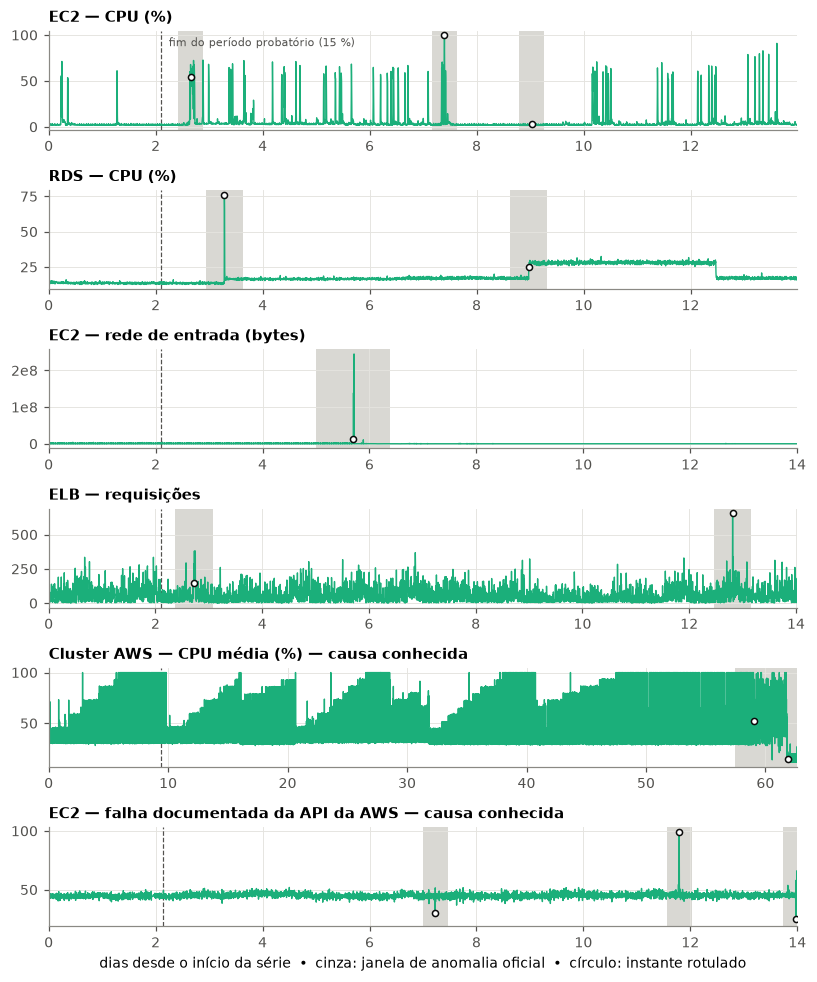

In [6]:
EXEMPLOS = [
    ("realAWSCloudwatch/ec2_cpu_utilization_fe7f93.csv", "EC2 — CPU (%)"),
    ("realAWSCloudwatch/rds_cpu_utilization_e47b3b.csv", "RDS — CPU (%)"),
    ("realAWSCloudwatch/ec2_network_in_257a54.csv", "EC2 — rede de entrada (bytes)"),
    ("realAWSCloudwatch/elb_request_count_8c0756.csv", "ELB — requisições"),
    ("realKnownCause/cpu_utilization_asg_misconfiguration.csv", "Cluster AWS — CPU média (%) — causa conhecida"),
    ("realKnownCause/ec2_request_latency_system_failure.csv", "EC2 — falha documentada da API da AWS — causa conhecida"),
]

fig, axes = plt.subplots(len(EXEMPLOS), 1, figsize=(7.5, 9))
for ax, (key, titulo) in zip(axes, EXEMPLOS):
    d = load_nab(key)
    dias = (d.index - d.index[0]) / pd.Timedelta(days=1)
    for k in sorted(set(d["janela_anomalia"]) - {0}):
        dentro = dias[d["janela_anomalia"] == k]
        ax.axvspan(dentro.min(), dentro.max(), color=DESTAQUE, linewidth=0, zorder=0)
    ax.axvline(dias[int(NAB_PROBATIONARY * len(d))], color=CINZA, linewidth=0.8, linestyle="--")
    ax.plot(dias, d["value"], color=COR_NAB)
    ax.plot(dias[d["rotulo"] == 1], d.loc[d["rotulo"] == 1, "value"], linestyle="none", marker="o",
            markersize=4, markerfacecolor="white", markeredgecolor="#0b0b0b", markeredgewidth=1)
    ax.set_title(titulo)
    ax.set_xlim(0, dias.max())
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v) if abs(v) < 1e4 else f"{v:.0e}".replace("e+0", "e")))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v)))
axes[0].annotate("fim do período probatório (15 %)", xy=(dias[int(NAB_PROBATIONARY * len(d))], 1), xycoords=("data", "axes fraction"),
                 xytext=(4, -10), textcoords="offset points", fontsize=7.5, color=CINZA)
axes[-1].set_xlabel("dias desde o início da série  •  cinza: janela de anomalia oficial  •  círculo: instante rotulado")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_eda_nab_series_rotuladas.png")
plt.show()

## 4. Implicações para a fase 3

| Tema | Achado | Decisão |
|---|---|---|
| Unidades | Cada série tem sua unidade e escala | Um modelo por série; normalização ajustada por série |
| Treino | Primeiros 15 % sem rótulos (período probatório) | Treino = período probatório; teste = 85 % restantes com rótulos reais |
| Rótulos | Janelas largas (~10 % dos pontos) | Avaliação por evento: janela detectada se houver ≥ 1 alarme dentro dela; falso positivo = alarme fora de qualquer janela |
| Assimetria | Séries quase sempre perto de zero, com picos enormes | Avaliar escalonamento robusto (mediana/IQR) ou transformação log nessas séries |
| Rótulo inconsistente | 1 rótulo fora da janela (`iio_…NetworkIn`) | Usar as janelas oficiais; registrar como limitação |
| Série sem anomalia | `ec2_cpu_utilization_c6585a` | Entra só no cálculo de falsos positivos |